# Qualité vectorielle : diagnostiquer, réparer et contrôler
**Cartomize · Module M08**

Durée indicative : 30 minutes.

Ce cours suit une couche depuis le diagnostic des géométries jusqu'au contrôle topologique. Nous choisissons les règles de réparation et de dédoublonnage, consultons les décisions par entité, puis exécutons le même parcours sous forme de chaîne réutilisable.

Les données sont **entièrement simulées** : un polygone croisé, deux observations de la même parcelle, une parcelle distincte et un enregistrement sans géométrie. Un second petit jeu de rectangles permet de vérifier les surfaces des chevauchements et des lacunes à la main. Il ne représente aucun relevé de terrain.

L'environnement du [guide des tutoriels](../README.md) suffit ; Qt et les données locales des cours 11–12 ne sont pas requis. Chaque exécution crée un nouveau dossier sous `tutorials/outputs`, grâce à un répertoire temporaire nommé de façon unique. Le [guide du module](../../docs/VECTOR_QUALITY.md) détaille les paramètres, le terminal et la fenêtre.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.patches import Patch
from shapely.geometry import Polygon, box
from shapely.affinity import translate
from IPython.display import display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "course.py").is_file() or (p / "tutorials/course.py").is_file())
root = root if (root / "course.py").is_file() else root / "tutorials"
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from course import run_directory
import cartomize as cm

out = run_directory("14_qualite_vectorielle")
CRS = "EPSG:32733"  # Projection métrique choisie pour ces données simulées.
X0, Y0 = 300000.0, 9500000.0
shift = lambda geometry: translate(geometry, xoff=X0, yoff=Y0)
print("Version Cartomize :", cm.__version__)
print("Dossier de cette exécution :", out.name)

Version Cartomize : 1.5.0
Dossier de cette exécution : 14_qualite_vectorielle_54gy16xe


## 1. Examiner chaque entité avant de la modifier

`id_field` conserve un identifiant unique et renseigné. `source_row` indique la position dans l'entrée de l'opération, à partir de zéro ; ce n'est pas un FID permanent.

Le polygone croisé a une géométrie invalide. Les deux lignes `A_v1` et `A_v2` possèdent la même géométrie, mais des dates différentes. Le diagnostic les signale sans choisir automatiquement laquelle conserver.

In [2]:
bowtie = shift(Polygon([(0, 0), (4, 4), (0, 4), (4, 0), (0, 0)]))
square_a = shift(box(6, 0, 10, 4))
source = gpd.GeoDataFrame(
    {
        "identifiant": ["croise", "A_v1", "A_v2", "B", "sans_geom"],
        "parcelle": ["X", "A", "A", "B", "N"],
        "date_releve": ["2026-01-01", "2026-01-01", "2026-02-01", "2026-01-01", "2026-01-01"],
        "valeur": [10, 20, 25, 30, 0],
    },
    geometry=[bowtie, square_a, square_a, shift(box(10, 0, 14, 4)), None],
    crs=CRS,
)
audit = cm.audit_geometries(source, id_field="identifiant")
display(audit.report[["source_row", "feature_id", "status", "reason", "duplicate_of_row"]])
assert audit.summary["input_features"] == 5
assert audit.summary["invalid_geometries"] == 1
assert audit.summary["missing_geometries"] == 1
assert audit.summary["duplicate_geometries"] == 1
assert len(audit.data) == len(source)  # Le diagnostic ne retire aucune ligne.

,source_row,feature_id,status,reason,duplicate_of_row
0,0,croise,invalid,Self-intersection[300002 9500002],<NA>
1,1,A_v1,valid,Valid Geometry,<NA>
2,2,A_v2,duplicate,Valid Geometry,1
3,3,B,valid,Valid Geometry,<NA>
4,4,sans_geom,missing,Missing geometry,<NA>


## 2. Réparer avec une décision explicite

Nous écartons l'enregistrement sans géométrie dans une couche séparée. `linework` répare le polygone croisé à partir de ses arêtes. Le passage de Polygon à MultiPolygon est ici autorisé et inscrit dans le rapport.

Les deux triangles réparés ont une surface totale de **8 m²**. L'aire calculée sur le polygone initial invalide n'est pas une référence territoriale fiable : l'écart après réparation ne doit pas être interprété comme un gain d'occupation du sol.

In [3]:
repaired = cm.repair_geometries(
    source, id_field="identifiant", method="linework",
    missing="drop", empty="error", type_changes="allow", keep_collapsed=True,
)
display(repaired.report[[
    "feature_id", "decision", "retained", "before_geometry_type",
    "after_geometry_type", "before_area_m2", "after_area_m2", "area_delta_m2",
]])
assert len(repaired.data) == 4
assert repaired.rejected.identifiant.tolist() == ["sans_geom"]
assert repaired.data.geometry.is_valid.all()
crossed_repair = repaired.data.loc[repaired.data.identifiant == "croise"].geometry.iloc[0]
assert crossed_repair.geom_type == "MultiPolygon"
assert np.isclose(crossed_repair.area, 8.0)
assert source.geometry.iloc[0].is_valid is False  # La source est restée inchangée.

,feature_id,decision,retained,before_geometry_type,after_geometry_type,before_area_m2,after_area_m2,area_delta_m2
0,croise,repaired,True,Polygon,MultiPolygon,0.0,8.0,8.0
1,A_v1,unchanged,True,Polygon,Polygon,16.0,16.0,0.0
2,A_v2,unchanged,True,Polygon,Polygon,16.0,16.0,0.0
3,B,unchanged,True,Polygon,Polygon,16.0,16.0,0.0
4,sans_geom,dropped_missing,False,NaN,NaN,NaN,NaN,NaN


## 3. Choisir ce qui constitue un doublon

La règle de cet exercice est : **même parcelle et même géométrie XY**, puis conservation de l'observation la plus récente. La date sert au tri, pas à la comparaison. `keep="last"` avec tri croissant retient donc `A_v2`.

Si les deux dates devaient être analysées comme observations distinctes, il faudrait ajouter `date_releve` à `keys`. Les clés manquantes restent distinctes avec `null_keys="distinct"`. Les dates manquantes sont toujours triées en fin : les contrôler avant d'utiliser une règle de dernière observation.

In [4]:
unique = cm.deduplicate(
    repaired.data,
    keys=["parcelle"], geometry="topological", keep="last",
    order_by=["date_releve"], ascending=True,
    null_keys="distinct", id_field="identifiant",
)
display(unique.report[[
    "source_row", "source_id", "group_id", "group_size",
    "retained", "retained_id", "reason",
]])
assert unique.data.identifiant.tolist() == ["croise", "A_v2", "B"]
assert unique.rejected.identifiant.tolist() == ["A_v1"]
assert unique.data.loc[unique.data.identifiant == "A_v2", "valeur"].iloc[0] == 25
assert np.isclose(unique.data.geometry.area.sum(), 40.0)
comparison = pd.DataFrame({
    "Étape": ["Source", "Après réparation", "Après dédoublonnage"],
    "Enregistrements": [len(source), len(repaired.data), len(unique.data)],
    "Géométries invalides": [audit.summary["invalid_geometries"],
                             repaired.summary["output_invalid_geometries"],
                             int((~unique.data.geometry.is_valid).sum())],
})
display(comparison)

,source_row,source_id,group_id,group_size,retained,retained_id,reason
0,0,croise,1,1,True,croise,unique
1,1,A_v1,2,2,False,A_v2,duplicate_removed
2,2,A_v2,2,2,True,A_v2,duplicate_group_keep_last
3,3,B,3,1,True,B,unique


,Étape,Enregistrements,Géométries invalides
0,Source,5,1
1,Après réparation,4,0
2,Après dédoublonnage,3,0


## 4. Mesurer des anomalies topologiques connues

Une première bande couvre 4 × 10 = **40 m²**, une seconde 5 × 10 = **50 m²**. Leur chevauchement fait 1 × 10 = **10 m²** : l'union couvre donc **80 m²** de la référence de **100 m²**. La zone non couverte représente 20 m², dont 10 m² sont déclarés comme lacune légitime. Le contrôle doit signaler **10 m² de chevauchement et 10 m² de lacune restante**.

Les lacunes sont calculées dans une emprise explicitement fournie. Le seuil `min_area` est en m² et conserve les anomalies strictement supérieures au seuil. La tolérance `tolerance` concerne uniquement les extrémités des lignes (`dangles`) ; elle ne déplace pas les géométries.

In [5]:
coverage = gpd.GeoDataFrame(
    {"identifiant": ["ouest", "est"]},
    geometry=[shift(box(0, 0, 4, 10)), shift(box(3, 0, 8, 10))], crs=CRS,
)
reference = gpd.GeoDataFrame({"nom": ["Référence simulée"]},
                           geometry=[shift(box(0, 0, 10, 10))], crs=CRS)
allowed = gpd.GeoDataFrame({"nom": ["Lacune légitime simulée"]},
                         geometry=[shift(box(9, 0, 10, 10))], crs=CRS)
topology = cm.check_topology(
    coverage, id_field="identifiant",
    rules=["duplicates", "overlaps", "gaps", "outside"],
    reference=reference, allowed_gaps=allowed, min_area=0.0,
)
display(topology.report[["rule", "feature_id", "feature_id_other", "area_m2"]])
assert topology.summary["counts"] == {"duplicates": 0, "overlaps": 1, "gaps": 1, "outside": 0}
assert np.isclose(topology.report.loc[topology.report.rule == "overlaps", "area_m2"].sum(), 10.0)
assert np.isclose(topology.report.loc[topology.report.rule == "gaps", "area_m2"].sum(), 10.0)
assert np.isclose(coverage.geometry.union_all().area, 80.0)
print("Référence : 100 m² ; union : 80 m² ; lacune admise : 10 m².")

,rule,feature_id,feature_id_other,area_m2
0,overlaps,ouest,est,10.0
1,gaps,None,None,10.0


Référence : 100 m² ; union : 80 m² ; lacune admise : 10 m².


## 5. Localiser les changements et les anomalies

Les coordonnées sont décalées dans cette figure pour lire les distances relatives en mètres. Les données de calcul et les fichiers gardent leur SCR et leurs coordonnées d'origine. Le polygone croisé, les doublons et les lacunes correspondent à des problèmes différents.

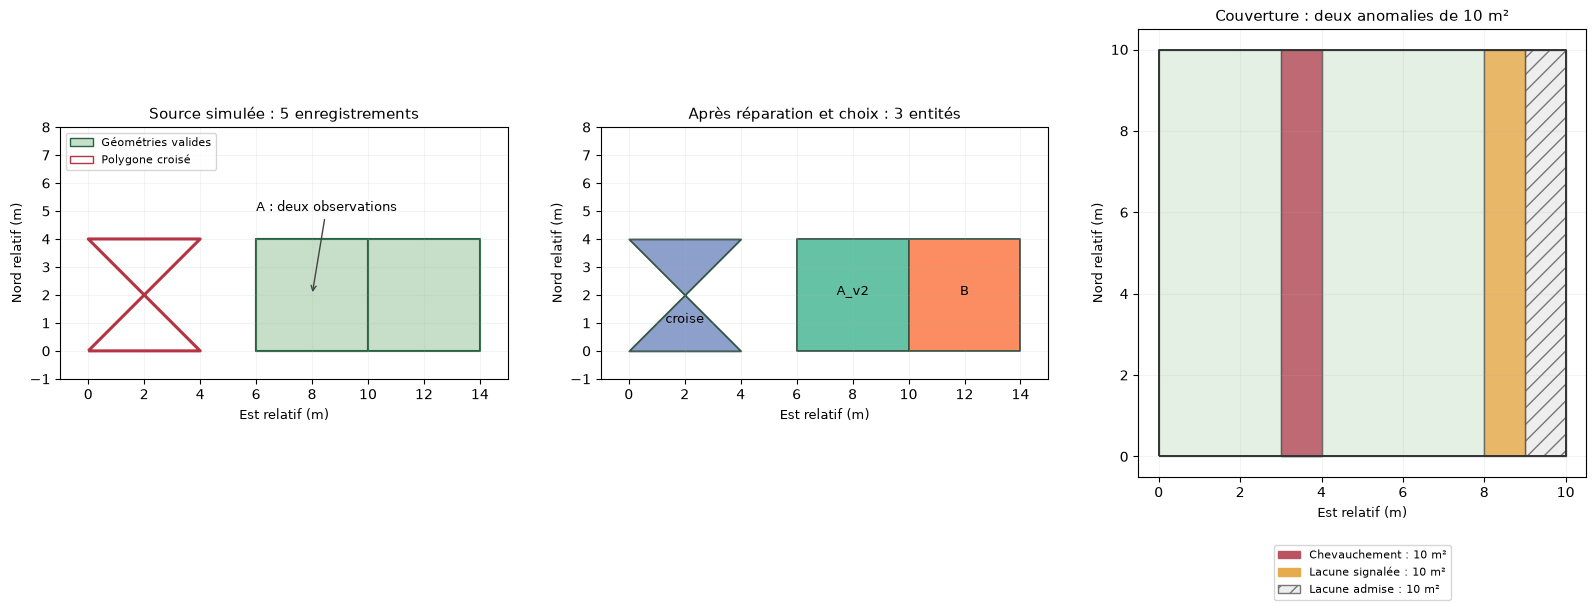

In [6]:
def local_view(data):
    view = data.copy()
    view.geometry = view.geometry.translate(xoff=-X0, yoff=-Y0)
    return view

fig, axes = plt.subplots(1, 3, figsize=(16, 6), layout="constrained")
fig.set_constrained_layout_pads(w_pad=.12, h_pad=.08, wspace=.08)
valid_source = source.loc[source.geometry.notna() & source.geometry.is_valid]
local_view(valid_source).plot(ax=axes[0], color="#c7dfc8", edgecolor="#256442", linewidth=1.5)
local_view(source.iloc[[0]]).boundary.plot(ax=axes[0], color="#b53343", linewidth=2.2)
axes[0].annotate("A : deux observations", xy=(8, 2), xytext=(6, 5),
                 arrowprops={"arrowstyle": "->", "color": "#444444"}, fontsize=9)
axes[0].set_title("Source simulée : 5 enregistrements", fontsize=11)
axes[0].legend(handles=[Patch(facecolor="#c7dfc8", edgecolor="#256442", label="Géométries valides"),
                       Patch(facecolor="none", edgecolor="#b53343", label="Polygone croisé")],
               loc="upper left", fontsize=8)

local_view(unique.data).plot(ax=axes[1], column="parcelle", categorical=True,
                            cmap="Set2", edgecolor="#345343", linewidth=1.3)
for row in local_view(unique.data).itertuples():
    point = row.geometry.representative_point()
    axes[1].annotate(row.identifiant, (point.x, point.y), ha="center", fontsize=9)
axes[1].set_title("Après réparation et choix : 3 entités", fontsize=11)

local_view(coverage).plot(ax=axes[2], color="#d8e8d8", edgecolor="#4d7552", alpha=.65)
local_view(reference).boundary.plot(ax=axes[2], color="#333333", linewidth=1.4)
local_view(allowed).plot(ax=axes[2], color="#eeeeee", edgecolor="#777777", hatch="//")
for rule, color in [("overlaps", "#ba5262"), ("gaps", "#e6ab4d")]:
    local_view(topology.data.loc[topology.data.rule == rule]).plot(
        ax=axes[2], color=color, edgecolor="#555555", alpha=.85)
axes[2].set_title("Couverture : deux anomalies de 10 m²", fontsize=11)
axes[2].legend(handles=[Patch(color="#ba5262", label="Chevauchement : 10 m²"),
                       Patch(color="#e6ab4d", label="Lacune signalée : 10 m²"),
                       Patch(facecolor="#eeeeee", edgecolor="#777777", hatch="//", label="Lacune admise : 10 m²")],
               loc="upper center", bbox_to_anchor=(.5, -.14), fontsize=8)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("Est relatif (m)", fontsize=9)
    ax.set_ylabel("Nord relatif (m)", fontsize=9)
    ax.grid(alpha=.15)
for ax in axes[:2]:
    ax.set_xlim(-1, 15)
    ax.set_ylim(-1, 8)
fig.savefig(out / "qualite_vectorielle.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Exécuter le même parcours dans une chaîne

Nous enregistrons la source simulée et une référence adaptée à sa propre emprise (14 × 4 = 56 m²). Après réparation et dédoublonnage, les géométries couvrent 40 m². La bande vide de 2 × 4 = 8 m² entre X et A est admise ; les deux triangles non couverts par X représentent donc **8 m² de lacune à signaler**.

La référence `@audit:data` transmet la source entière à la réparation. `@audit` transmettrait seulement les anomalies, car elles sont le résultat principal de l'audit enregistré. Les produits nommés permettent de choisir explicitement la couche à poursuivre.

In [7]:
source_path = out / "source_brute.gpkg"
reference_path = out / "reference_chaine.gpkg"
allowed_path = out / "lacune_admise_chaine.gpkg"
source.to_file(source_path, driver="GPKG", index=False)
gpd.GeoDataFrame(geometry=[shift(box(0, 0, 14, 4))], crs=CRS).to_file(
    reference_path, driver="GPKG", index=False)
gpd.GeoDataFrame(geometry=[shift(box(4, 0, 6, 4))], crs=CRS).to_file(
    allowed_path, driver="GPKG", index=False)

steps = [
    dict(id="audit", operation="vector.audit_geometries",
         parameters=dict(data=str(source_path), id_field="identifiant")),
    dict(id="reparation", operation="vector.repair_geometries",
         parameters=dict(data="@audit:data", id_field="identifiant", missing="drop",
                         empty="error", type_changes="allow", method="linework")),
    dict(id="uniques", operation="vector.deduplicate",
         parameters=dict(data="@reparation:data", id_field="identifiant", keys=["parcelle"],
                         geometry="topological", keep="last", order_by=["date_releve"])),
    dict(id="topologie", operation="vector.check_topology",
         parameters=dict(data="@uniques:data", id_field="identifiant",
                         rules=["duplicates", "overlaps", "gaps", "outside"],
                         reference=str(reference_path), allowed_gaps=str(allowed_path))),
]
plan = cm.processing_plan(steps)
manifest = cm.run_plan(plan, out / "chaine_complete")
record = json.loads(manifest.read_text(encoding="utf-8"))
print("Chaîne terminée :", manifest.name)

Chaîne terminée : automation.json


## 7. Relire les sorties et préparer leur utilisation

Chaque étape produit une couche principale, un rapport CSV, un résumé JSON et les couches associées. Les objets écartés restent disponibles. Pour la topologie, les produits `data` et `issues` partagent le même fichier ; les chemins du manifeste font référence.

Les assertions suivantes comparent les résultats du plan aux appels Python précédents et aux surfaces attendues. Le cours contrôle ainsi les données réellement enregistrées.

In [8]:
products = record["products"]
from_chain = gpd.read_file(products["uniques"]["data"])
assert from_chain.identifiant.tolist() == unique.data.identifiant.tolist()
np.testing.assert_allclose(from_chain.geometry.area, unique.data.geometry.area)
chain_topology = gpd.read_file(products["topologie"]["data"])
assert np.isclose(chain_topology.loc[chain_topology.rule == "gaps", "area_m2"].sum(), 8.0)
assert gpd.read_file(products["reparation"]["rejected"]).identifiant.tolist() == ["sans_geom"]
assert gpd.read_file(products["uniques"]["rejected"]).identifiant.tolist() == ["A_v1"]
assert all(Path(path).is_file() for result in products.values() for path in result.values())

file_table = pd.DataFrame([
    {"Étape": stage, "Produit": name, "Fichier": Path(path).name}
    for stage, files in products.items()
    for name, path in files.items() if name in {"data", "issues", "rejected", "report", "summary"}
])
display(file_table)
cli_parameters = out / "audit_cli.json"
cli_parameters.write_text(json.dumps({
    "data": str(source_path), "id_field": "identifiant",
}, ensure_ascii=False, indent=2), encoding="utf-8")
print("Commande équivalente pour le diagnostic (choisir un nouveau dossier) :")
print(f'cartomize process vector.audit_geometries "{cli_parameters}" "{out / "audit_terminal"}"')
print("Figure enregistrée : qualite_vectorielle.png")

,Étape,Produit,Fichier
0,audit,data,data.gpkg
1,audit,issues,issues.gpkg
2,audit,rejected,rejected.gpkg
3,audit,report,report.csv
4,audit,summary,summary.json
5,reparation,data,data.gpkg
6,reparation,issues,issues.gpkg
7,reparation,rejected,rejected.gpkg
8,reparation,report,report.csv
9,reparation,summary,summary.json


Commande équivalente pour le diagnostic (choisir un nouveau dossier) :
cartomize process vector.audit_geometries "tutorials/outputs/14_qualite_vectorielle_54gy16xe/audit_cli.json" "tutorials/outputs/14_qualite_vectorielle_54gy16xe/audit_terminal"
Figure enregistrée : qualite_vectorielle.png


## Retrouver ces règles dans la fenêtre

Dans **Traitements vectoriels**, choisir **Diagnostic détaillé des géométries**, **Réparation avec rapport des changements**, **Contrôle topologique** ou **Traitement des doublons**. Renseigner la source, les règles, le répertoire parent et un nouveau dossier de résultats. Les champs de comparaison des doublons et les champs de tri sont deux choix séparés. Dans **Chaîne de traitements**, les mêmes opérateurs acceptent les produits nommés des étapes précédentes.

**Exercice.** Relancer le dédoublonnage avec `keys=["parcelle", "date_releve"]`. Combien de lignes restent ?

**Réponse.** Quatre : les deux observations de A ont des dates distinctes et ne constituent plus un groupe dupliqué selon cette définition. La règle doit être choisie avant l'analyse.

### Références et conventions

- [Shapely — `make_valid`](https://shapely.readthedocs.io/en/stable/reference/shapely.make_valid.html) : méthodes de réparation et composantes effondrées.
- [QGIS 3.44 — contrôle topologique](https://docs.qgis.org/3.44/en/docs/user_manual/plugins/core_plugins/plugins_topology_checker.html) : règles de couverture et interprétation métier des extrémités pendantes.
- [Shapely — égalité topologique](https://shapely.readthedocs.io/en/stable/reference/shapely.Polygon.html) : égalité XY distincte de l'identité des coordonnées.
- [Guide Cartomize M08](../../docs/VECTOR_QUALITY.md) : contrats exacts des paramètres, unités, identifiants et produits.